In [1]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import imageio
import os
from scipy.signal import convolve2d
from pathlib import Path
from progressbar import progressbar

start_scope()

DATA_PATH = Path('data') 
TRAIN_IMG_PATH = DATA_PATH / 'train_images'

n_rc=14
n_input_rows = n_rc-2  
n_input_columns = n_rc-2  
n_output_rows = n_rc-4  
n_output_columns = n_rc-4  
N_inp = n_input_rows*n_input_columns
N_E = n_output_rows*n_output_columns

# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -55. * mV
V_E = 0.0 * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.2 * nF

# membrane leak
g_m_E = 25. * nS
g_m_I = 20. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# external stimuli
rate = 3 * Hz
C_ext = 800


# AMPA
g_AMPA_ext_E = 20.8 * nS #2.08
g_AMPA_rec_E = 0.104 * nS 
g_AMPA_ext_I = 1.62 * nS
g_AMPA_rec_I = 0.081 * nS 
tau_AMPA = 2. * ms


# GABAa
g_GABA_E = 1.25*nS #1.25 * nS 0.8
g_GABA_I = 1.25*nS #0.973 * nS 0.8
tau_GABA = 10. * ms


#STDP/iSTDP
Apre = 0.012
Apost = -0.0115 
w_max = 1.5 #3


# Apre_i = -0.005   
# Apost_i = 0.005
Apre_i = -0.011   
Apost_i = 0.015
w_max_i = 5.0

#gif 
save_interval = 0.5*second  
frames_test = []
frames_train = []
rf_indices = [1,25,33,46,53,64,77,85,96]
center_neurons = [15, 24, 45, 65, 89]

def capture_rf_weights_for_gif(t, C_PG_E, output_indices, frames_list, n_input_columns, receptive_field_size=3):
    conn_data = C_PG_E.get_states(['i', 'j', 'w'])  # Sparse connection data
    
    fig, axs = plt.subplots(1, len(output_indices), figsize=(10 , 10)) #* len(output_indices)
    if len(output_indices) == 1:
        axs = [axs]  # Make iterable
    
    for ax, out_idx in zip(axs, output_indices):
        # Get input indices and weights projecting to output neuron out_idx
        input_indices = conn_data['i'][conn_data['j'] == out_idx]
        weights = conn_data['w'][conn_data['j'] == out_idx]
        
        # Convert flat indices to (row, col) based on image shape
        input_coords = np.array([[idx // n_input_columns, idx % n_input_columns] for idx in input_indices])

        # Normalize so smallest coord is (0, 0)
        base_coords = np.min(input_coords, axis=0)
        rf_matrix = np.zeros((receptive_field_size, receptive_field_size))

        for coord, w in zip(input_coords, weights):
            row, col = coord - base_coords
            if 0 <= row < receptive_field_size and 0 <= col < receptive_field_size:
                rf_matrix[row, col] = w

        ax.imshow(rf_matrix, cmap='hot', vmin=0, vmax=w_max, interpolation='nearest', aspect='equal')
        ax.set_title(f"Neuron {out_idx}", fontsize=8)
        ax.axis('off')

    fig.suptitle(f'Receptive Fields at t = {t/ms:.0f} ms')
    fig.tight_layout(pad=0.01)  
    
    # Store frame
    frames_list.append(fig)
    plt.close()

frames_rec=[]
recurrent_radius = 2
def plot_connection_groups_gif(t, center_neurons, synapses, n_output_columns,frames_list):
    conn_data = synapses.get_states(['i', 'j', 'w'])

    fig, axes = plt.subplots(1, len(center_neurons), figsize=(10, 10))
    
    for idx, center in enumerate(center_neurons):
        cx, cy = divmod(center, n_output_columns)
        rf_matrix = np.zeros((recurrent_radius*2+1, recurrent_radius*2+1))

        for dx in range(-recurrent_radius, recurrent_radius + 1):
            for dy in range(-recurrent_radius, recurrent_radius + 1):
                ix, iy = cx + dx, cy + dy
                if 0 <= ix < n_output_columns and 0 <= iy < n_output_columns:
                    input_idx = ix * n_output_columns + iy
                    mask = (conn_data['i'] == input_idx) & (conn_data['j'] == center)
                    if np.any(mask):
                        rf_matrix[dx + recurrent_radius, dy +recurrent_radius] = conn_data['w'][mask][0]

        ax = axes[idx]
        ax.imshow(rf_matrix, cmap='hot', vmin=0, vmax=w_max,interpolation='nearest', aspect='equal')
        ax.set_title(f'N {center}', fontsize=8)
        ax.axis('off')
    fig.suptitle(f'Recurrent Fields at t = {t/ms:.0f} ms')
    fig.tight_layout(pad=0.01)  
    
    # Store frame
    frames_list.append(fig)
    plt.close()


kill_mask = np.ones((n_input_rows, n_input_columns), dtype=np.float32)
kill_mask[3, 5] = 0
kill_mask[6, 7] = 0
kill_mask[2, 3] = 0
kill_mask[6, 8] = 0


def create_mexican_hat_kernel():
    from scipy.ndimage import gaussian_filter
    center = np.zeros((3,3))
    center[1,1] = 1.0
    g1 = gaussian_filter(center, sigma=0.5)
    g2 = gaussian_filter(center, sigma=1.0)
    return g1 - g2
kernel = create_mexican_hat_kernel() 


def apply_mexican_hat(img):
    filtered = convolve2d(img, kernel, mode='valid')  
    return filtered


def generate_bar_image(shape=(n_rc, n_rc), n_bars=3):
    img = np.zeros(shape, dtype=np.float32)
    orientation = np.random.choice(['horizontal', 'vertical', 'diagonal'])

    for _ in range(n_bars):
        if orientation == 'horizontal':
            row = np.random.randint(1, shape[0]-1)
            img[row, :] = 1.0
        elif orientation == 'vertical':
            col = np.random.randint(1, shape[1]-1)
            img[:, col] = 1.0
        elif orientation == 'diagonal':
            shift = np.random.randint(-shape[0]//2, shape[0]//2)
            for i in range(shape[0]):
                j = i + shift
                if 0 <= j < shape[1]:
                    img[i, j] = 1.0
    return img


def mexican_hat(img):
    filtered = convolve2d(img, kernel, mode='valid')  
    return filtered

def convert_to_rates(filtered_img, max_rate=50):
    norm_img = filtered_img - np.min(filtered_img)
    norm_img /= np.max(norm_img)
    rates = norm_img.flatten() * max_rate * Hz
    return rates

def load_npy(path):
    arr = np.load(path)
    print('Loading', path, arr.shape)
    return arr

def save_npy(arr, path):
    arr = np.array(arr)
    print('Saving', arr.shape, path)
    np.save(path, arr)

def normalize_plastic_weights(syns, target_total=1.0):
    conns = np.reshape(syns.w, (N_inp, N_E))

    col_sums = np.sum(conns, axis=0)
    col_sums[col_sums == 0] = 1.0
    factors = target_total / col_sums
    conns *= factors
    syns.w = conns.reshape(-1)#conns.flatten()

def build_network(training):
    # variables
    n_input_rows = n_rc-2  
    n_input_columns = n_rc-2  
    n_output_rows = n_rc-4  
    n_output_columns = n_rc-4  
    N_inp = n_input_rows*n_input_columns
    N_E = n_output_rows*n_output_columns
    N_I = int(N_inp * 0.2)  
    target_rate = 5*Hz
    alpha = 0.05 #0.1
    window = 1*second
    plasticity_dt = 100*ms
    max_gate = 3

    # voltage
    V_L = -70. * mV
    V_thr = -50. * mV
    V_reset = -55. * mV
    V_E = 0.0 * mV
    V_I = -70. * mV

    # membrane capacitance
    C_m_E = 0.5 * nF
    C_m_I = 0.2 * nF

    # membrane leak
    g_m_E = 25. * nS
    g_m_I = 20. * nS

    # refractory period
    tau_rp_E = 2. * ms
    tau_rp_I = 1. * ms

    # external stimuli
    rate = 3 * Hz
    C_ext = 800

    # synapses
    C_E = N_E
    C_I = N_I

    # AMPA
    g_AMPA_ext_E = 20.8 * nS #2.08
    g_AMPA_rec_E = 0.104 * nS 
    g_AMPA_ext_I = 1.62 * nS
    g_AMPA_rec_I = 0.081 * nS 
    tau_AMPA = 2. * ms


    # GABAa
    g_GABA_E = 1.25*nS #1.25 * nS 
    g_GABA_I = 1.25*nS #0.973 * nS 
    tau_GABA = 10. * ms


    # modeling
    eqs_E = '''
    dv / dt = (- g_m_E * (v - V_L) - I_syn) / C_m_E : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
    I_AMPA_ext = g_AMPA_ext_E * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_E * (v - V_E) * 1 * s_AMPA : amp
    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt = - s_AMPA / tau_AMPA : 1
    I_GABA_rec = g_GABA_E * (v - V_I) * s_GABA : amp
    ds_GABA / dt = - s_GABA / tau_GABA : 1
    '''

    eqs_I = '''
    dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
    I_AMPA_ext = g_AMPA_ext_I * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_I * (v - V_E) * 1 * s_AMPA : amp
    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt = - s_AMPA / tau_AMPA : 1
    I_GABA_rec = g_GABA_I * (v - V_I) * s_GABA : amp
    ds_GABA / dt = - s_GABA / tau_GABA : 1
    '''

    P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_E, method='euler')
    P_E.v = V_L
    P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_I, method='euler')
    P_I.v = V_L

    #STDP
    stdp_eqs = '''
    w : 1
    dpre/dt = -pre/ taupre : 1 (event-driven)
    dpost/dt = -post/ taupost : 1 (event-driven)
    taupre : second (constant)
    taupost : second (constant)
    '''


    on_pre_stdp = '''
    s_AMPA += w
    pre += 1.
    w = clip(w + Apost * post, 0, w_max)
    '''

    on_post_stdp = '''
    post += 1.
    w = clip(w + Apre * pre, 0, w_max)
    '''
    #iSTDP
    iSTDP_eqs = '''
    w : 1
    dpre/dt = -pre / taupre : 1 (event-driven)
    dpost/dt = -post / taupost : 1 (event-driven)
    taupre : second (constant)
    taupost : second (constant)
    '''

    on_pre_iSTDP = '''
    s_GABA += w
    pre += 1.
    w = clip(w + Apost_i * post, 0, w_max_i)
    '''

    on_post_iSTDP = '''
    post += 1.
    w = clip(w + Apre_i * pre, 0, w_max_i)
    '''


    #E1
    # E to E
    C_E_E = Synapses(P_E, P_E,
                    model=stdp_eqs,
                    on_pre=on_pre_stdp,
                    on_post=on_post_stdp,
                    method='euler',
                    name='E_E')
    #C_E_E.connect('i != j')
    recurrent_radius = 2
    for y1 in range(n_output_rows):
        for x1 in range(n_output_columns):
            post = y1 * n_output_columns + x1
            for dy in range(-recurrent_radius, recurrent_radius + 1):
                for dx in range(-recurrent_radius, recurrent_radius + 1):
                    if dx == 0 and dy == 0:
                        continue
                    x2 = x1 + dx
                    y2 = y1 + dy
                    if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                        pre = y2 * n_output_columns + x2
                        C_E_E.connect(i=pre, j=post)

    C_E_E.taupre = 20*ms
    C_E_E.taupost = 20*ms

    # E to I
    C_E_I = Synapses(P_E, P_I,
                    model=stdp_eqs,
                    on_pre=on_pre_stdp,
                    on_post=on_post_stdp,
                    method='euler',
                    name='E_I')
    C_E_I.connect()
    C_E_I.taupre = 20*ms
    C_E_I.taupost = 20*ms

    # I to I
    C_I_I = Synapses(P_I, P_I,
                    model=iSTDP_eqs,
                    on_pre=on_pre_iSTDP,
                    on_post=on_post_iSTDP,
                    method='euler',
                    name='I_I')
    C_I_I.connect('i != j')
    C_I_I.taupre = 20*ms
    C_I_I.taupost = 20*ms

    # I to E
    C_I_E = Synapses(P_I, P_E,
                    model=iSTDP_eqs,
                    on_pre=on_pre_iSTDP,
                    on_post=on_post_iSTDP,
                    method='euler',
                    name='I_E')
    C_I_E.connect()
    C_I_E.taupre = 20*ms
    C_I_E.taupost = 20*ms

    #pattern
    #pg_inp = PoissonGroup(N_inp, rates='input_rate_timed(t, i) * Hz', name = 'inp')
    pg_inp = PoissonGroup(N_inp, rates=0 * Hz, name = 'inp')

    C_PG_E = Synapses(pg_inp, P_E, model = stdp_eqs, on_pre='''
            s_AMPA_ext += w
            pre += 1.
            w = clip(w + Apost * post, 0, 1.5)
        ''',
        on_post='''
            post += 1.
            w = clip(w + Apre * pre, 0, 1.5)
        ''',
        method='euler', name='PG_E')
    C_PG_E.connect(False)  

    rf_size = 3  
    half_rf = rf_size // 2


    for out_y in range(n_output_rows):
        for out_x in range(n_output_columns):
            out_index = out_y * n_output_columns + out_x  
            for dx in range(3):  
                for dy in range(3):
                    in_x = out_x + dx
                    in_y = out_y + dy
                    if 0 <= in_x < n_input_columns and 0 <= in_y < n_input_rows:
                        in_index = in_y * n_input_columns + in_x  
                        C_PG_E.connect(i=in_index, j=out_index)       
                        print(f"Output neuron {out_index} is connected to input neurons: {in_index}")
             

    C_PG_E.taupre = 20*ms
    C_PG_E.taupost = 20*ms
    if training:
        C_PG_E.w[:] = 0.7
        C_I_E.w[:] = 1
        C_I_I.w[:] = 1
        C_E_I.w[:] = 1
        C_E_E.w[:] = 1
    else:
        w_PG_E = load_npy(DATA_PATH / 'w_PG_E.npy')
        w_I_E = load_npy(DATA_PATH / 'w_I_E.npy')
        w_I_I = load_npy(DATA_PATH / 'w_I_I.npy')
        w_E_I = load_npy(DATA_PATH / 'w_E_I.npy')
        w_E_E = load_npy(DATA_PATH / 'w_E_E.npy')
        C_PG_E.w[:] = w_PG_E
        C_I_E.w[:] = w_I_E
        C_I_I.w[:] = w_I_I
        C_E_I.w[:] = w_E_I
        C_E_E.w[:] = w_E_E

    # external noise
    #C_P_E = PoissonInput(P_E, 's_AMPA_ext', C_ext, rate, '1')
    C_P_I = PoissonInput(P_I, 's_AMPA_ext', C_ext, rate, '1')


    # monitors

    sp_E = SpikeMonitor(P_E, name = 'sp_exc')
    sp_I = SpikeMonitor(P_I, name = 'sp_inh')

    r_E = PopulationRateMonitor(P_E)
    r_I = PopulationRateMonitor(P_I)

    # mon_C_E_E = StateMonitor(C_E_E, 'w', record=True)
    mon_C_PG_E = StateMonitor(C_E_E, 'w', record=True)

    # mon_C_E_I = StateMonitor(C_E_I, 'w', record=True)
    # mon_C_I_E = StateMonitor(C_I_E, 'w', record=True)
    # mon_C_I_I = StateMonitor(C_I_I, 'w', record=True)


    # @network_operation(dt=save_interval)
    # def capture_frames():
    #     plot_weights_for_gif(defaultclock.t)


    if training == 0 :
        C_E_E.pre.code = 's_AMPA += w'  
        C_E_E.post.code = ''
        C_E_I.pre.code = 's_AMPA += w'
        C_E_I.post.code = ''
        C_I_E.pre.code = 's_GABA += w'  
        C_I_E.post.code = ''
        C_I_I.pre.code = 's_GABA += w'  
        C_I_I.post.code = ''
        C_PG_E.pre.code = 's_AMPA_ext += w'  
        C_PG_E.post.code = ''
    @network_operation(dt=save_interval)
    def capture_rf_frames_train():
        if training == 0 :
            return
        capture_rf_weights_for_gif(defaultclock.t, net['PG_E'], rf_indices, frames_train, n_input_columns)
    

    @network_operation(dt=save_interval)
    def capture_rf_frames_test():
        if training == 1 :
            return
        capture_rf_weights_for_gif(defaultclock.t, net['PG_E'], rf_indices, frames_test, n_input_columns)

    @network_operation(dt=save_interval)
    def capture_conn_frames():
        plot_connection_groups_gif(defaultclock.t, center_neurons, net['E_E'], n_output_columns, frames_list=frames_rec)

    @network_operation(dt=plasticity_dt)
    def homeostatic_plasticity():
        if training == 1 :
            return
        t_now = defaultclock.t
        if t_now < window:
            return
        t0 = t_now - window
        #E
        times = sp_E.t
        idxs  = sp_E.i
        rates = np.zeros(N_E)*Hz
        for post in range(N_E):
            mask = np.logical_and(idxs == post, times >= t0)
            count = np.sum(mask)
            rates[post] = count/window
            delta = np.clip((target_rate - rates[post]) / target_rate, -1.0, 1.0)
            for pre in range(N_E):
                if pre == post:
                    continue
                C_E_E.w[pre, post] = clip(C_E_E.w[pre, post]+ alpha * delta, 0, w_max)
            for pre in range(N_I):
                C_I_E.w[pre, post] = clip(C_I_E.w[pre, post] - alpha * delta, 0, w_max)
            for pre in range(N_I):
                C_E_I.w[post, pre] = clip(C_E_I.w[post, pre] - alpha * delta, 0, w_max)
        print(f"[{t_now/ms:.0f} ms]  "
              f"rates (mean): {np.mean(rates):.1f} Hz  ")  
        #I
        times1 = sp_E.t
        idxs1  = sp_E.i
        rates1 = np.zeros(N_E)*Hz
        rates2 = np.zeros(N_E)*Hz
        for post in range(N_E):  
            mask1 = np.logical_and(idxs1 == post, times1 >= t0)
            count1 = np.sum(mask1)
            rates1[post] = count1 / window
        avg_rate_E = np.mean(rates1) 
        C_I_I.w[:] = clip(C_I_I.w[:] - alpha * (avg_rate_E - target_rate) / target_rate, 0, w_max_i)

    net = Network(collect())
    net.run(0*ms, report='stdout') # 
    return net



def show_img(net, index):
    filtered = load_npy(TRAIN_IMG_PATH / f'img_{index:03d}.npy')
    rate_img = convert_to_rates(filtered)
    net['inp'].rates = rate_img
    net.run(500*ms)
    # net['inp'].rates = 5 * Hz
    # net.run(500 * ms)
    net['inp'].rates = 0 * Hz
    net.run(250 * ms)

def show_img_mask(net, index):
    filtered = load_npy(TRAIN_IMG_PATH / f'img_{index:03d}.npy')
    filtered *= kill_mask
    rate_img = convert_to_rates(filtered)
    net['inp'].rates = rate_img
    net.run(500*ms)



def train(N_train):
    net = build_network(True)
    for i in range(N_train): #progressbar(
        show_img(net, index = i)
        #normalize_plastic_weights(net['PG_E'])
        print(i)

    save_npy(net['PG_E'].w, DATA_PATH / 'w_PG_E.npy')
    save_npy(net['E_E'].w, DATA_PATH / 'w_E_E.npy')    
    save_npy(net['I_E'].w, DATA_PATH / 'w_I_E.npy')    
    save_npy(net['E_I'].w, DATA_PATH / 'w_E_I.npy')   
    save_npy(net['I_I'].w, DATA_PATH / 'w_I_I.npy')    
    return net



def test(N_test):
    net = build_network(False)
    for i in range(N_test):
        show_img_mask(net, index=i)
        print(f"Tested image {i+1}/{N_test}")
    return net

def create_gif_from_frames(frames, filename='rf_evolution_train.gif', duration=0.1):
    with imageio.get_writer(filename, mode='I', duration=duration) as writer:
        for idx, frame in enumerate(frames):
            temp_path = f'temp_frame_{idx}.png'
            frame.savefig(temp_path, bbox_inches='tight', pad_inches=0.1)
            image = imageio.imread(temp_path)
            writer.append_data(image)
            os.remove(temp_path)

    print(f"✅ GIF saved as: {filename}")

    



INFO       Cache size for target 'cython': 1224 MB.
You can call clear_cache('cython') to delete all files from the cache or manually delete files in the '/home/vincent/.cython/brian_extensions' directory. [brian2]


INFO:root:creating /tmp/brian_flag_test_fv2seqwi/tmp
INFO:root:creating /tmp/brian_flag_test_fv2seqwi/tmp/brian_flag_test_fv2seqwi
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_fv2seqwi/flag_test.cpp -o /tmp/brian_flag_test_fv2seqwi/tmp/brian_flag_test_fv2seqwi/flag_test.o -w
INFO:root:creating /tmp/brian_flag_test_4f97hycp/tmp
INFO:root:creating /tmp/brian_flag_test_4f97hycp/tmp/brian_flag_test_4f97hycp
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_4f97hycp/flag_test.cpp -o /tmp/brian_flag_test_4f97hycp/tmp/brian_flag_test_4f97hycp/flag_test.o -O3
INFO:root:creating /tmp/brian_flag_test_84h0vr2e/tmp
INFO:root:creating /tmp/brian_flag_test_84h0vr2e/tmp/brian_flag_test_84h0vr2e
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_84h0vr2e/flag_test.cpp -o /tmp/brian_flag_test_84

Output neuron 0 is connected to input neurons: 0
Output neuron 0 is connected to input neurons: 12
Output neuron 0 is connected to input neurons: 24
Output neuron 0 is connected to input neurons: 1
Output neuron 0 is connected to input neurons: 13
Output neuron 0 is connected to input neurons: 25
Output neuron 0 is connected to input neurons: 2
Output neuron 0 is connected to input neurons: 14
Output neuron 0 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 1
Output neuron 1 is connected to input neurons: 13
Output neuron 1 is connected to input neurons: 25
Output neuron 1 is connected to input neurons: 2
Output neuron 1 is connected to input neurons: 14
Output neuron 1 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 3
Output neuron 1 is connected to input neurons: 15
Output neuron 1 is connected to input neurons: 27
Output neuron 2 is connected to input neurons: 2
Output neuron 2 is connected to input neurons: 14
Output 

WARNING    'post' is an internal variable of group 'E_E', but also exists in the run namespace with the value 99. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'pre' is an internal variable of group 'E_E', but also exists in the run namespace with the value 98. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'post' is an internal variable of group 'E_I', but also exists in the run namespace with the value 99. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'pre' is an internal variable of group 'E_I', but also exists in the run namespace with the value 98. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'post' is an internal variable of group 'I_E', but also exists in the run namespace with the value 99. The internal variable will be used. [brian2.groups.group.Group.r

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s
Loading data/train_images/img_000.npy (12, 12)
0
Loading data/train_images/img_001.npy (12, 12)
1
Loading data/train_images/img_002.npy (12, 12)
2
Loading data/train_images/img_003.npy (12, 12)
3
Loading data/train_images/img_004.npy (12, 12)
4
Loading data/train_images/img_005.npy (12, 12)
5
Loading data/train_images/img_006.npy (12, 12)
6
Loading data/train_images/img_007.npy (12, 12)
7
Loading data/train_images/img_008.npy (12, 12)
8
Loading data/train_images/img_009.npy (12, 12)
9
Loading data/train_images/img_010.npy (12, 12)
10
Loading data/train_images/img_011.npy (12, 12)
11
Loading data/train_images/img_012.npy (12, 12)
12
Loading data/train_images/img_013.npy (12, 12)
13
Loading data/train_images/img_014.npy (12, 12)
14
Loading data/train_images/img_015.npy (12, 12)
15
Loading data/train_images/img_016.npy (12, 12)
16
Loading data/train_images/img_017.npy (12, 12)
17
Loading data/train_images/i

WARNING    /home/vincent/bmnn/lib/python3.12/site-packages/brian2tools/plotting/data.py:59: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "." (-> marker='.'). The keyword argument will take precedence.
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)
 [py.warnings]
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)



39
Saving (900,) data/w_PG_E.npy
Saving (1836,) data/w_E_E.npy
Saving (2800,) data/w_I_E.npy
Saving (2800,) data/w_E_I.npy
Saving (756,) data/w_I_I.npy


WARNING    /tmp/ipykernel_34302/3476348737.py:603: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = imageio.imread(temp_path)
 [py.warnings]
  image = imageio.imread(temp_path)



✅ GIF saved as: rf_evolution_train.gif
✅ GIF saved as: recf_evolution_train.gif


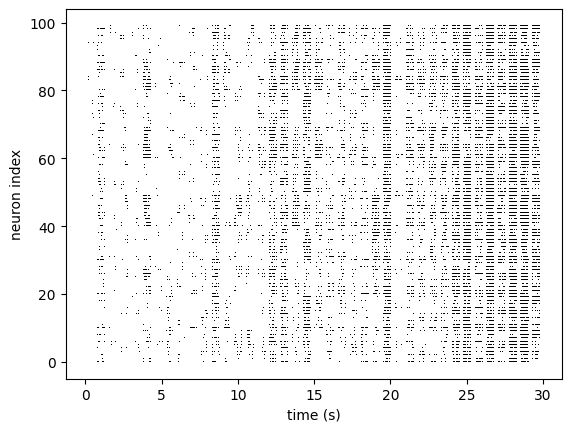

In [2]:
start_scope()
net = train(40)
exc_mon = net['sp_exc']
#inh_mon=net['sp_inh']
plot_raster(exc_mon.i, exc_mon.t, time_unit=second, marker=',', color='k')
create_gif_from_frames(frames_train)
create_gif_from_frames(frames_rec,filename='recf_evolution_train.gif')

#plot_raster(inh_mon.i, inh_mon.t, time_unit=second, marker=',', color='k')

<Axes: xlabel='time (s)', ylabel='neuron index'>

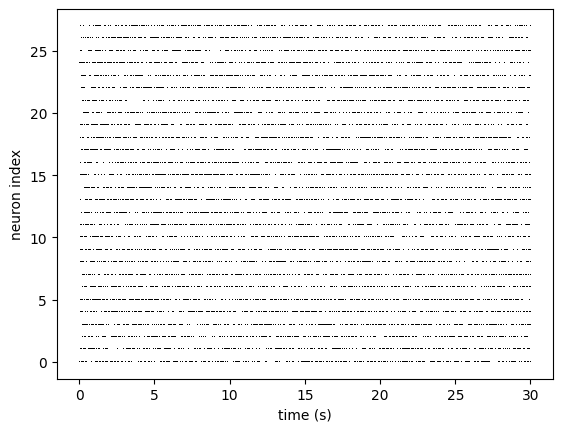

In [ ]:
inh_mon=net['sp_inh']
plot_raster(inh_mon.i, inh_mon.t, time_unit=second, marker=',', color='k')


Output neuron 0 is connected to input neurons: 0
Output neuron 0 is connected to input neurons: 12
Output neuron 0 is connected to input neurons: 24
Output neuron 0 is connected to input neurons: 1
Output neuron 0 is connected to input neurons: 13
Output neuron 0 is connected to input neurons: 25
Output neuron 0 is connected to input neurons: 2
Output neuron 0 is connected to input neurons: 14
Output neuron 0 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 1
Output neuron 1 is connected to input neurons: 13
Output neuron 1 is connected to input neurons: 25
Output neuron 1 is connected to input neurons: 2
Output neuron 1 is connected to input neurons: 14
Output neuron 1 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 3
Output neuron 1 is connected to input neurons: 15
Output neuron 1 is connected to input neurons: 27
Output neuron 2 is connected to input neurons: 2
Output neuron 2 is connected to input neurons: 14
Output 

WARNING    /tmp/ipykernel_34302/3476348737.py:603: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = imageio.imread(temp_path)
 [py.warnings]
  image = imageio.imread(temp_path)



✅ GIF saved as: rf_evolution_test.gif
✅ GIF saved as: recf_evolution_test.gif


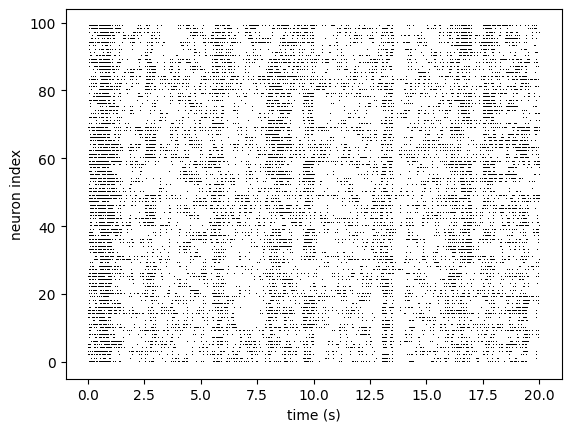

In [3]:
start_scope()
net = test(40)
exc_mon = net['sp_exc']
plot_raster(exc_mon.i, exc_mon.t, time_unit=second, marker=',', color='k')
create_gif_from_frames(frames_test,filename='rf_evolution_test.gif')
create_gif_from_frames(frames_rec,filename='recf_evolution_test.gif')



In [14]:
w_PG_E = load_npy(DATA_PATH / 'w_PG_E.npy')
w_I_E = load_npy(DATA_PATH / 'w_I_E.npy')
w_I_I = load_npy(DATA_PATH / 'w_I_I.npy')
w_E_I = load_npy(DATA_PATH / 'w_E_I.npy')
w_E_E = load_npy(DATA_PATH / 'w_E_E.npy')
print(w_PG_E)
print(w_I_E)
print(w_I_I)
print(w_E_I)
print(w_E_E)

Loading data/w_PG_E.npy (900,)
Loading data/w_I_E.npy (2800,)
Loading data/w_I_I.npy (756,)
Loading data/w_E_I.npy (2800,)
Loading data/w_E_E.npy (1836,)
[1.36858104 1.5        1.49497122 1.48231995 1.46676664 1.20415517
 1.37441452 1.33770636 1.26613797 1.23032805 1.48958026 1.11824637
 1.16712656 1.13398214 1.03607763 1.45190641 1.20891587 1.26252535
 1.2864582  1.05252866 0.97803113 1.10169531 0.88125228 1.00233588
 0.84556751 1.0199434  0.98109507 1.44240584 1.20476071 1.31003702
 1.25630354 1.47761628 1.16001717 1.26319091 1.42258399 1.20386557
 1.5        1.20525465 1.45228593 1.30071704 1.23742071 1.21123557
 1.46900184 1.5        1.49475462 1.480859   1.46654078 1.36459148
 1.28163584 1.5        1.17079705 1.30650208 1.40792023 1.45695564
 1.5        1.48328298 1.28152537 1.49913033 1.49460072 1.05044794
 1.18452252 1.5        1.49849649 1.49185938 1.49560985 1.27387502
 1.13201059 1.46333505 1.3392764  1.48691524 1.49777004 1.48912763
 1.43454743 1.5        1.5        1.5     

In [2]:
TRAIN_IMG_PATH = DATA_PATH / 'train_images'
TRAIN_IMG_PATH.mkdir(parents=True, exist_ok=True)
for index in range(100):
    img = generate_bar_image((n_rc, n_rc), 3)
    filtered = mexican_hat(img)
    save_npy(filtered, TRAIN_IMG_PATH / f'img_{index:03d}.npy')

Saving (12, 12) data/train_images/img_000.npy
Saving (12, 12) data/train_images/img_001.npy
Saving (12, 12) data/train_images/img_002.npy
Saving (12, 12) data/train_images/img_003.npy
Saving (12, 12) data/train_images/img_004.npy
Saving (12, 12) data/train_images/img_005.npy
Saving (12, 12) data/train_images/img_006.npy
Saving (12, 12) data/train_images/img_007.npy
Saving (12, 12) data/train_images/img_008.npy
Saving (12, 12) data/train_images/img_009.npy
Saving (12, 12) data/train_images/img_010.npy
Saving (12, 12) data/train_images/img_011.npy
Saving (12, 12) data/train_images/img_012.npy
Saving (12, 12) data/train_images/img_013.npy
Saving (12, 12) data/train_images/img_014.npy
Saving (12, 12) data/train_images/img_015.npy
Saving (12, 12) data/train_images/img_016.npy
Saving (12, 12) data/train_images/img_017.npy
Saving (12, 12) data/train_images/img_018.npy
Saving (12, 12) data/train_images/img_019.npy
Saving (12, 12) data/train_images/img_020.npy
Saving (12, 12) data/train_images/

Loading data/train_images/img_001.npy (12, 12)


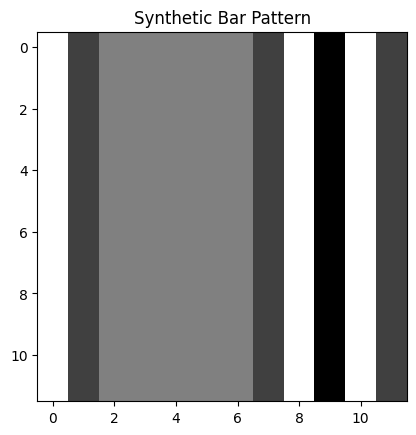

In [6]:
filtered = load_npy(TRAIN_IMG_PATH / f'img_{1:03d}.npy')
rate_img = convert_to_rates(filtered)

plt.imshow(filtered, cmap='gray')
plt.title("Synthetic Bar Pattern")
plt.show()
